**Mount Google Drive**

In [ ]:
# Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

print("✅ Google Drive mounted successfully!")

Mounted at /content/drive
✅ Google Drive mounted successfully!


**Find the ZIP file**

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith('.zip'):
            print(os.path.join(root, file))

/content/drive/MyDrive/Img and Vdo Project/BharathPothole.zip


**Extract dataset**

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Img and Vdo Project/BharathPothole.zip"
extract_path = "/content/BharathPothole"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted to:", extract_path)

Dataset extracted to: /content/BharathPothole


**Inspect folder structure**

In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

BharathPothole/
  BharatPotHole/
    BharatPotHole/


**Count files by type**

In [ ]:
from collections import Counter

file_types = Counter()

for root, dirs, files in os.walk(extract_path):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        file_types[ext] += 1

print(file_types)

Counter({'.txt': 7076, '.jpg': 7074, '.cache': 2, '.yaml': 1})


**Show sample files**

In [ ]:
for root, dirs, files in os.walk(extract_path):
    for file in files[:10]:
        print(os.path.join(root, file))

/content/BharathPothole/BharatPotHole/BharatPotHole/README.roboflow.txt
/content/BharathPothole/BharatPotHole/BharatPotHole/data.yaml
/content/BharathPothole/BharatPotHole/BharatPotHole/README.dataset.txt
/content/BharathPothole/BharatPotHole/BharatPotHole/valid/labels.cache
/content/BharathPothole/BharatPotHole/BharatPotHole/valid/images/signal-2025-06-25-183557_frame_00035_jpg.rf.7f777e1b6894e82bd39a4ec8df314ceb.jpg
/content/BharathPothole/BharatPotHole/BharatPotHole/valid/images/20250626065234_0060_frame_00080_jpg.rf.e5cf026b5055f4528d4fc0af62a7dbc8.jpg
/content/BharathPothole/BharatPotHole/BharatPotHole/valid/images/20250518150306_0060_frame_00028_jpg.rf.10fd04cfe1e338ee908fe06e47fed71d.jpg
/content/BharathPothole/BharatPotHole/BharatPotHole/valid/images/20250530165658_0060_frame_00044_jpg.rf.f66b5036aadb84a56327394859a58098.jpg
/content/BharathPothole/BharatPotHole/BharatPotHole/valid/images/20250626065434_0060_frame_00039_jpg.rf.9bf7ab0925d3e2af975b8dd433cbc83e.jpg
/content/Bhara

**Read data.yaml**

In [ ]:
import yaml

DATASET = "/content/BharathPothole/BharatPotHole/BharatPotHole"

with open(f"{DATASET}/data.yaml", "r") as f:
    data = yaml.safe_load(f)

data

{'train': '../train/images',
 'val': '../valid/images',
 'test': '../test/images',
 'nc': 1,
 'names': ['pothole'],
 'roboflow': {'workspace': 'yolo-ewrwa',
  'project': 'dashcam-mg6en',
  'version': 14,
  'license': 'CC BY 4.0',
  'url': 'https://universe.roboflow.com/yolo-ewrwa/dashcam-mg6en/dataset/14'}}

**Count images and labels in each split**

In [ ]:
import os

splits = ["train", "valid", "test"]

for split in splits:
    image_dir = f"{DATASET}/{split}/images"
    label_dir = f"{DATASET}/{split}/labels"

    images = [f for f in os.listdir(image_dir) if f.lower().endswith(".jpg")]
    labels = [f for f in os.listdir(label_dir) if f.lower().endswith(".txt")]

    print(f"{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print()

TRAIN
Images: 5067
Labels: 5067

VALID
Images: 1345
Labels: 1345

TEST
Images: 662
Labels: 662



**Analyze bounding-box distribution**

In [ ]:
from collections import Counter
import numpy as np

for split in splits:
    label_dir = f"{DATASET}/{split}/labels"

    widths = []
    heights = []
    areas = []
    box_counts = []

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, file), "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        box_counts.append(len(lines))

        for line in lines:
            values = line.split()

            if len(values) == 5:
                _, _, _, w, h = map(float, values)
                widths.append(w)
                heights.append(h)
                areas.append(w * h)

    print(f"{split.upper()}")
    print("Total bounding boxes:", len(areas))
    print("Average boxes/image:", np.mean(box_counts))
    print("Average box width:", np.mean(widths))
    print("Average box height:", np.mean(heights))
    print("Average relative box area:", np.mean(areas))
    print()

TRAIN
Total bounding boxes: 8519
Average boxes/image: 1.7357410696664692
Average box width: 0.07723250968423524
Average box height: 0.041187804466486684
Average relative box area: 0.004784105777572558

VALID
Total bounding boxes: 2210
Average boxes/image: 1.692193308550186
Average box width: 0.08354814762443438
Average box height: 0.04012195984162896
Average relative box area: 0.004664927486920249

TEST
Total bounding boxes: 1121
Average boxes/image: 1.7371601208459215
Average box width: 0.08787494424620874
Average box height: 0.04029535570918823
Average relative box area: 0.004456958073148974



**Visualize sample annotations**

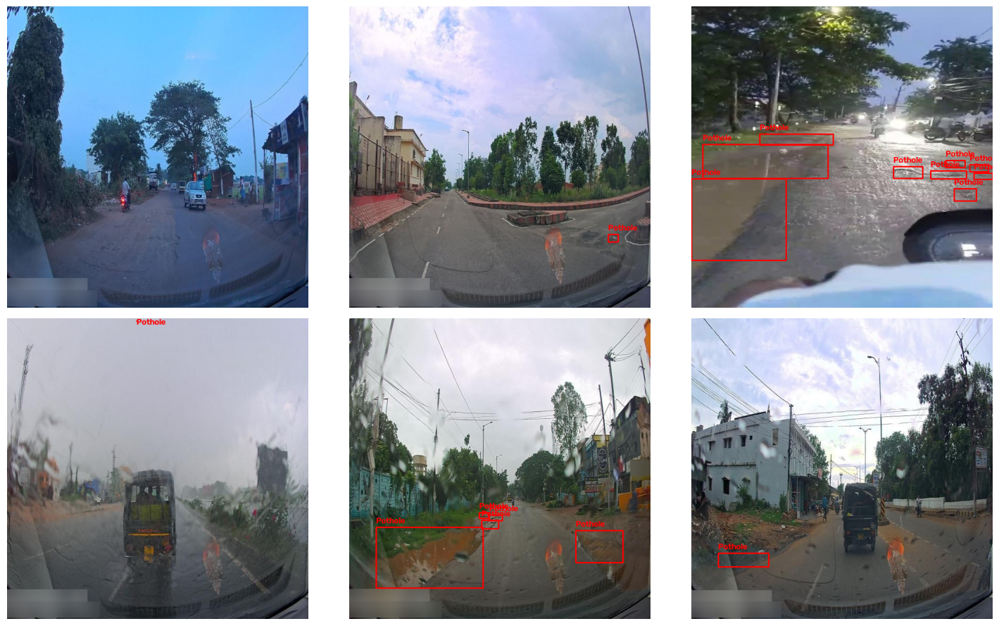

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

image_dir = f"{DATASET}/train/images"
label_dir = f"{DATASET}/train/labels"

image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith(".jpg")
]

samples = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_file in zip(axes.ravel(), samples):
    image_path = os.path.join(image_dir, image_file)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(image_file)[0] + ".txt"
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                values = line.split()

                if len(values) != 5:
                    continue

                _, x, y, bw, bh = map(float, values)

                x1 = int((x - bw / 2) * w)
                y1 = int((y - bh / 2) * h)
                x2 = int((x + bw / 2) * w)
                y2 = int((y + bh / 2) * h)

                cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(
                    image,
                    "Pothole",
                    (x1, max(y1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 0, 0),
                    2
                )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Check image dimensions and annotation validity**

In [ ]:
import os
import cv2
import numpy as np

image_dir = f"{DATASET}/train/images"
label_dir = f"{DATASET}/train/labels"

widths = []
heights = []
invalid_boxes = 0

for image_file in os.listdir(image_dir):
    if not image_file.lower().endswith(".jpg"):
        continue

    image = cv2.imread(os.path.join(image_dir, image_file))

    if image is None:
        continue

    h, w = image.shape[:2]
    widths.append(w)
    heights.append(h)

    label_file = os.path.splitext(image_file)[0] + ".txt"
    label_path = os.path.join(label_dir, label_file)

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                values = line.split()

                if len(values) != 5:
                    invalid_boxes += 1
                    continue

                cls, x, y, bw, bh = map(float, values)

                if not (
                    0 <= cls < data["nc"]
                    and 0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < bw <= 1
                    and 0 < bh <= 1
                ):
                    invalid_boxes += 1

print("Number of images checked:", len(widths))
print("Image width:", min(widths), "to", max(widths))
print("Image height:", min(heights), "to", max(heights))
print("Most common image size:", max(set(zip(widths, heights)), key=list(zip(widths, heights)).count))
print("Invalid annotations:", invalid_boxes)

Number of images checked: 5067
Image width: 640 to 640
Image height: 640 to 640
Most common image size: (640, 640)
Invalid annotations: 276


**Identify why annotations are marked invalid**

In [ ]:
from collections import Counter

label_dir = f"{DATASET}/train/labels"

issues = Counter()
examples = []

for file in os.listdir(label_dir):
    if not file.endswith(".txt"):
        continue

    with open(os.path.join(label_dir, file), "r") as f:
        for line_no, line in enumerate(f, 1):
            values = line.split()

            if len(values) != 5:
                issues["wrong number of values"] += 1
                continue

            cls, x, y, bw, bh = map(float, values)

            if not (0 <= cls < data["nc"]):
                issues["invalid class"] += 1
                if len(examples) < 5:
                    examples.append((file, line_no, line.strip()))

            elif not (0 <= x <= 1):
                issues["x outside range"] += 1
                if len(examples) < 5:
                    examples.append((file, line_no, line.strip()))

            elif not (0 <= y <= 1):
                issues["y outside range"] += 1
                if len(examples) < 5:
                    examples.append((file, line_no, line.strip()))

            elif not (0 < bw <= 1):
                issues["width outside range"] += 1
                if len(examples) < 5:
                    examples.append((file, line_no, line.strip()))

            elif not (0 < bh <= 1):
                issues["height outside range"] += 1
                if len(examples) < 5:
                    examples.append((file, line_no, line.strip()))

print("Annotation issues:")
for issue, count in issues.items():
    print(issue, ":", count)

print("\nExample problematic annotations:")
for example in examples:
    print(example)

Annotation issues:
wrong number of values : 276

Example problematic annotations:


**Inspect malformed annotations**

In [ ]:
label_dir = f"{DATASET}/train/labels"

malformed = []

for file in os.listdir(label_dir):
    if not file.endswith(".txt"):
        continue

    with open(os.path.join(label_dir, file), "r") as f:
        for line_no, line in enumerate(f, 1):
            values = line.split()

            if len(values) != 5:
                malformed.append({
                    "file": file,
                    "line": line_no,
                    "values": values,
                    "count": len(values)
                })

print("Total malformed lines:", len(malformed))

for item in malformed[:20]:
    print(
        item["file"],
        "| line:", item["line"],
        "| values:", item["values"],
        "| count:", item["count"]
    )

Total malformed lines: 276
20250523182911_0060_frame_00045_jpg.rf.3782eed88c484c36c8fe45eea6cadeb6.txt | line: 1 | values: ['0', '0.1889', '0.85649305625', '0.19284765625', '0.8171796296875', '0.14389557343749998', '0.8115629625', '0.136', '0.7947143515625', '0.04125390625', '0.79611851875', '0.0118432296875', '0.8372745374999999', '0.064940625', '0.8986148140625', '0.10915546875', '0.8915949078125', '0.1786359375', '0.890190740625', '0.1889', '0.85649305625'] | count: 21
20250523182911_0060_frame_00045_jpg.rf.3782eed88c484c36c8fe45eea6cadeb6.txt | line: 2 | values: ['0', '0.3689174484375', '0.7610166671874999', '0.3452309890625', '0.7722490734375', '0.29312057343750003', '0.7846379625', '0.34049375', '0.8270078703125', '0.3807606765625', '0.8115629625', '0.39497265625', '0.782077778125', '0.3689174484375', '0.7610166671874999'] | count: 15
20250523182911_0060_frame_00045_jpg.rf.3782eed88c484c36c8fe45eea6cadeb6.txt | line: 3 | values: ['0', '0.3562846359375', '0.741359721875', '0.35470

**Convert polygon annotations to bounding boxes**

In [ ]:
import os
import shutil

for split in splits:
    label_dir = f"{DATASET}/{split}/labels"
    backup_dir = f"{DATASET}/{split}/labels_original"

    if not os.path.exists(backup_dir):
        shutil.copytree(label_dir, backup_dir)

    converted = 0

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        label_path = os.path.join(label_dir, file)

        with open(label_path, "r") as f:
            lines = f.readlines()

        new_lines = []

        for line in lines:
            values = line.split()

            if len(values) == 5:
                new_lines.append(line.strip())
                continue

            if len(values) > 5 and (len(values) - 1) % 2 == 0:
                cls = values[0]
                points = list(map(float, values[1:]))

                xs = points[0::2]
                ys = points[1::2]

                x1 = max(0.0, min(xs))
                y1 = max(0.0, min(ys))
                x2 = min(1.0, max(xs))
                y2 = min(1.0, max(ys))

                x_center = (x1 + x2) / 2
                y_center = (y1 + y2) / 2
                width = x2 - x1
                height = y2 - y1

                new_lines.append(
                    f"{cls} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}"
                )

                converted += 1

        with open(label_path, "w") as f:
            f.write("\n".join(new_lines) + "\n")

    print(f"{split.upper()}: converted {converted} polygon annotations")

TRAIN: converted 276 polygon annotations
VALID: converted 66 polygon annotations
TEST: converted 29 polygon annotations


**Verify the labels are now valid**

In [ ]:
for split in splits:
    label_dir = f"{DATASET}/{split}/labels"

    malformed = 0
    total_boxes = 0

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, file), "r") as f:
            for line in f:
                values = line.split()

                if len(values) != 5:
                    malformed += 1
                    continue

                cls, x, y, w, h = map(float, values)

                if not (
                    0 <= cls < data["nc"]
                    and 0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < w <= 1
                    and 0 < h <= 1
                ):
                    malformed += 1
                else:
                    total_boxes += 1

    print(f"{split.upper()}")
    print("Valid bounding boxes:", total_boxes)
    print("Invalid annotations:", malformed)
    print()

TRAIN
Valid bounding boxes: 8795
Invalid annotations: 2000

VALID
Valid bounding boxes: 2276
Invalid annotations: 589

TEST
Valid bounding boxes: 1150
Invalid annotations: 289



**Find the remaining invalid annotations**

In [ ]:
for split in splits:
    label_dir = f"{DATASET}/{split}/labels"

    issues = Counter()

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, file), "r") as f:
            for line in f:
                values = line.split()

                if len(values) != 5:
                    issues[f"{len(values)} values"] += 1
                    continue

                cls, x, y, w, h = map(float, values)

                if not (0 <= cls < data["nc"]):
                    issues["invalid class"] += 1
                elif not (0 <= x <= 1):
                    issues["x outside range"] += 1
                elif not (0 <= y <= 1):
                    issues["y outside range"] += 1
                elif not (0 < w <= 1):
                    issues["width outside range"] += 1
                elif not (0 < h <= 1):
                    issues["height outside range"] += 1

    print(f"\n{split.upper()}")
    for issue, count in issues.items():
        print(issue, ":", count)


TRAIN
0 values : 2000

VALID
0 values : 589

TEST
0 values : 289


**Show actual remaining problematic lines**

In [ ]:
for split in splits:
    label_dir = f"{DATASET}/{split}/labels"

    examples = []

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, file), "r") as f:
            for line_no, line in enumerate(f, 1):
                values = line.split()

                invalid = False

                if len(values) != 5:
                    invalid = True
                else:
                    cls, x, y, w, h = map(float, values)

                    if not (
                        0 <= cls < data["nc"]
                        and 0 <= x <= 1
                        and 0 <= y <= 1
                        and 0 < w <= 1
                        and 0 < h <= 1
                    ):
                        invalid = True

                if invalid:
                    examples.append(
                        (file, line_no, values)
                    )

                if len(examples) >= 10:
                    break

            if len(examples) >= 10:
                break

    print(f"\n{split.upper()} - First 10 problematic annotations")

    for file, line_no, values in examples:
        print(file)
        print("Line:", line_no)
        print("Values:", values)
        print("Count:", len(values))
        print()


TRAIN - First 10 problematic annotations
20250522114600_0060_frame_00001_jpg.rf.ba5d63bd6b62baab5038fa3154a4264e.txt
Line: 1
Values: []
Count: 0

20250507080126_0060_frame_00004_jpg.rf.4562fc9d5740454e5ec1c507836d7b91.txt
Line: 1
Values: []
Count: 0

20250507075626_0060_frame_00095_jpg.rf.379a819637172612c478038d62609e70.txt
Line: 1
Values: []
Count: 0

20250530165658_0060_frame_00062_jpg.rf.32e6e118dcfa213ef31895054a2ed30c.txt
Line: 1
Values: []
Count: 0

20250507074926_0060_frame_00060_jpg.rf.2eaa3707280c74742fc45cbeaa74e0ac.txt
Line: 1
Values: []
Count: 0

20250524105539_0060_frame_00003_jpg.rf.19a48a1e0180e9ea9cefee0cfbef1cde.txt
Line: 1
Values: []
Count: 0

20250503174729_0060_frame_00006_jpg.rf.e93bff9c479843c1e862484480805d93.txt
Line: 1
Values: []
Count: 0

signal-2025-06-25-151313_frame_00066_jpg.rf.159e95ac6c60dddd48f9ca27672c6732.txt
Line: 1
Values: []
Count: 0

20250518150306_0060_frame_00041_jpg.rf.be80723dfaff363ca85d3e76111c5a05.txt
Line: 1
Values: []
Count: 0

20250518

**Final dataset summary**

In [ ]:
for split in splits:
    image_dir = f"{DATASET}/{split}/images"
    label_dir = f"{DATASET}/{split}/labels"

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(".jpg")
    ]

    images_with_potholes = 0
    images_without_potholes = 0
    total_boxes = 0

    for image_file in image_files:
        label_file = os.path.splitext(image_file)[0] + ".txt"
        label_path = os.path.join(label_dir, label_file)

        boxes = 0

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    if len(line.split()) == 5:
                        boxes += 1

        total_boxes += boxes

        if boxes > 0:
            images_with_potholes += 1
        else:
            images_without_potholes += 1

    print(f"{split.upper()}")
    print("Total images:", len(image_files))
    print("Images with potholes:", images_with_potholes)
    print("Images without potholes:", images_without_potholes)
    print("Total bounding boxes:", total_boxes)
    print()

TRAIN
Total images: 5067
Images with potholes: 3067
Images without potholes: 2000
Total bounding boxes: 8795

VALID
Total images: 1345
Images with potholes: 756
Images without potholes: 589
Total bounding boxes: 2276

TEST
Total images: 662
Images with potholes: 373
Images without potholes: 289
Total bounding boxes: 1150



**Visualize the cleaned annotations**

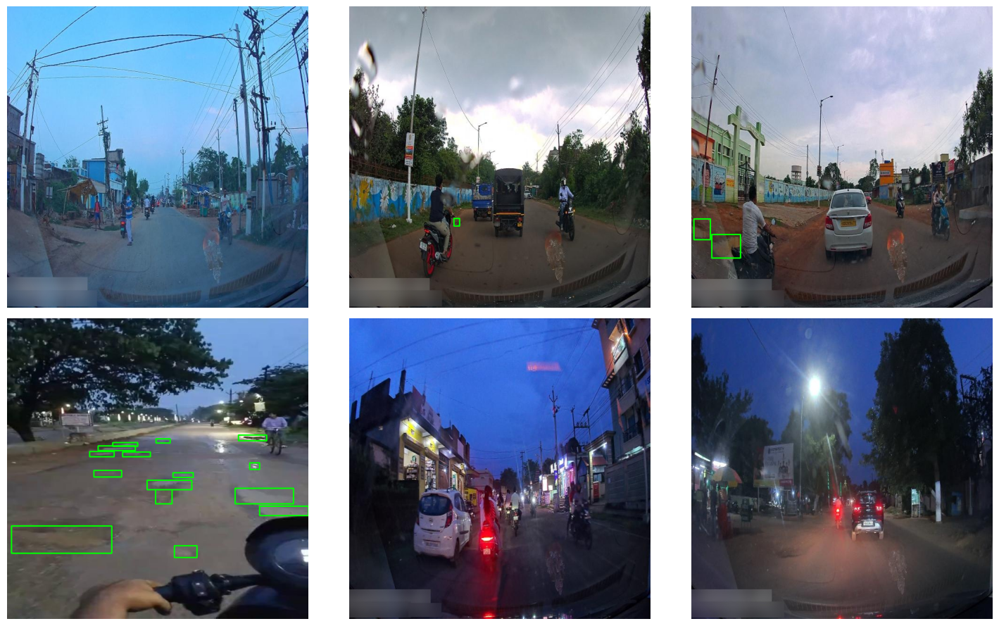

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

image_dir = f"{DATASET}/train/images"
label_dir = f"{DATASET}/train/labels"

image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith(".jpg")
]

samples = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_file in zip(axes.ravel(), samples):
    image_path = os.path.join(image_dir, image_file)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(image_file)[0] + ".txt"
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                values = line.split()

                if len(values) != 5:
                    continue

                _, x, y, bw, bh = map(float, values)

                x1 = int((x - bw / 2) * w)
                y1 = int((y - bh / 2) * h)
                x2 = int((x + bw / 2) * w)
                y2 = int((y + bh / 2) * h)

                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Create training configuration**

In [ ]:
import yaml
import os

TRAIN_YAML = "/content/BharathPothole/bharatpothole_train.yaml"

train_config = {
    "path": DATASET,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["pothole"]
}

with open(TRAIN_YAML, "w") as f:
    yaml.dump(train_config, f, sort_keys=False)

print("Training YAML created:")
print(TRAIN_YAML)

with open(TRAIN_YAML, "r") as f:
    print(f.read())

Training YAML created:
/content/BharathPothole/bharatpothole_train.yaml
path: /content/BharathPothole/BharatPotHole/BharatPotHole
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- pothole



**Verify training paths**

In [ ]:
with open(TRAIN_YAML, "r") as f:
    config = yaml.safe_load(f)

for split in ["train", "val", "test"]:
    path = os.path.join(config["path"], config[split])
    print(split.upper(), ":", path)
    print("Exists:", os.path.exists(path))

TRAIN : /content/BharathPothole/BharatPotHole/BharatPotHole/train/images
Exists: True
VAL : /content/BharathPothole/BharatPotHole/BharatPotHole/valid/images
Exists: True
TEST : /content/BharathPothole/BharatPotHole/BharatPotHole/test/images
Exists: True


**Install Ultralytics**

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 8.2 MB/s eta 0:00:00


**Verify YOLO installation and GPU**

In [ ]:
import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.150
GPU available: True
GPU: Tesla T4


**Load the YOLO model**

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Model loaded successfully")

Model loaded successfully


**Verify the model and dataset together**

In [ ]:
model.info()

print("\nDataset configuration:")
print("Train:", config["train"])
print("Validation:", config["val"])
print("Test:", config["test"])
print("Classes:", config["names"])

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs

Dataset configuration:
Train: train/images
Validation: valid/images
Test: test/images
Classes: ['pothole']


**Run a pretrained baseline**

In [ ]:
baseline = model.val(
    data=TRAIN_YAML,
    split="val",
    imgsz=640,
    batch=16,
    device=0
)

print("Baseline mAP50:", baseline.box.map50)
print("Baseline mAP50-95:", baseline.box.map)

Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2135.1±726.7 MB/s, size: 113.6 KB)
val: Scanning /content/BharathPothole/BharatPotHole/BharatPotHole/valid/labels... 1345 images, 589 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1345/1345 2.7Kit/s 0.5s
val: New cache created: /content/BharathPothole/BharatPotHole/BharatPotHole/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 85/85 4.9it/s 17.4s
                   all       1345       2276   4.81e-05    0.00176   2.67e-07   5.34e-08
                person        756       2276   4.81e-05    0.00176   2.67e-07   5.34e-08
Speed: 1.9ms preprocess, 4.3ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val
Baseline mAP50: 2.671867902850883e-07
Baseline mAP50-95: 5

Your dataset has only one class, pothole, but YOLO is reporting the class as person. That means the pretrained COCO class names are being used during validation instead of our dataset class name.

The extremely low baseline mAP is therefore not meaningful yet. We should fix the class mapping first.

**Verify the YAML and model class mapping**

In [ ]:
print("TRAIN_YAML CONTENT:\n")

with open(TRAIN_YAML, "r") as f:
    print(f.read())

print("\nMODEL CLASSES:")
print(model.names)

TRAIN_YAML CONTENT:

path: /content/BharathPothole/BharatPotHole/BharatPotHole
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- pothole


MODEL CLASSES:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

**Force the model to use the pothole class**

In [ ]:
model.model.names = {0: "pothole"}

print("Model classes:")
print(model.model.names)

Model classes:
{0: 'pothole'}


**Check the model configuration**

In [ ]:
print("Number of classes:", model.model.nc)
print("Class names:", model.model.names)

Number of classes: 80
Class names: {0: 'pothole'}


**Training**

In [ ]:
results = model.train(
    data=TRAIN_YAML,
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=5,
    project="/content/roadvision_runs",
    name="pothole_yolo11n",
    exist_ok=True
)

Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BharathPothole/bharatpothole_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pothole_yolo11n, nbs=64, nms

**Load the best trained model**

In [ ]:
from ultralytics import YOLO

BEST_MODEL = "/content/roadvision_runs/pothole_yolo11n/weights/best.pt"

best_model = YOLO(BEST_MODEL)

print("Best model loaded successfully")
print("Model path:", BEST_MODEL)

Best model loaded successfully
Model path: /content/roadvision_runs/pothole_yolo11n/weights/best.pt


**Evaluate on the test set**

In [ ]:
test_results = best_model.val(
    data=TRAIN_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 20.0±8.4 MB/s, size: 116.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/BharathPothole/BharatPotHole/BharatPotHole/test/labels... 662 images, 289 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 662/662 419.3it/s 1.6s
val: New cache created: /content/BharathPothole/BharatPotHole/BharatPotHole/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 5.4it/s 7.7s
                   all        662       1150      0.511       0.41        0.4      0.135
Speed: 2.1ms preprocess, 4.0ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/runs/detect/val-3

**Run predictions on unseen test images**

In [ ]:
test_image_dir = f"{DATASET}/test/images"

test_predictions = best_model.predict(
    source=test_image_dir,
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/roadvision_runs",
    name="test_predictions",
    exist_ok=True
)

print("Test predictions completed")


image 1/662 /content/BharathPothole/BharatPotHole/BharatPotHole/test/images/20250501091922_0060_frame_00021_jpg.rf.5b0c19144874e900e7127b3da0cd04c4.jpg: 640x640 (no detections), 41.6ms
image 2/662 /content/BharathPothole/BharatPotHole/BharatPotHole/test/images/20250501091922_0060_frame_00040_jpg.rf.1abcc8ff2712d8f906ef07c5b3cfbfaa.jpg: 640x640 (no detections), 22.4ms
image 3/662 /content/BharathPothole/BharatPotHole/BharatPotHole/test/images/20250501091922_0060_frame_00052_jpg.rf.29d1a6ab35a65b7a45cbf0202e2d2a40.jpg: 640x640 (no detections), 17.1ms
image 4/662 /content/BharathPothole/BharatPotHole/BharatPotHole/test/images/20250501091922_0060_frame_00064_jpg.rf.eed54ae511eed0c22cf1c40735d93b31.jpg: 640x640 (no detections), 16.1ms
image 5/662 /content/BharathPothole/BharatPotHole/BharatPotHole/test/images/20250501091922_0060_frame_00070_jpg.rf.4b05c993a310013aa848c81e2ada96f6.jpg: 640x640 (no detections), 19.7ms
image 6/662 /content/BharathPothole/BharatPotHole/BharatPotHole/test/image

**Display test predictions with green boxes**

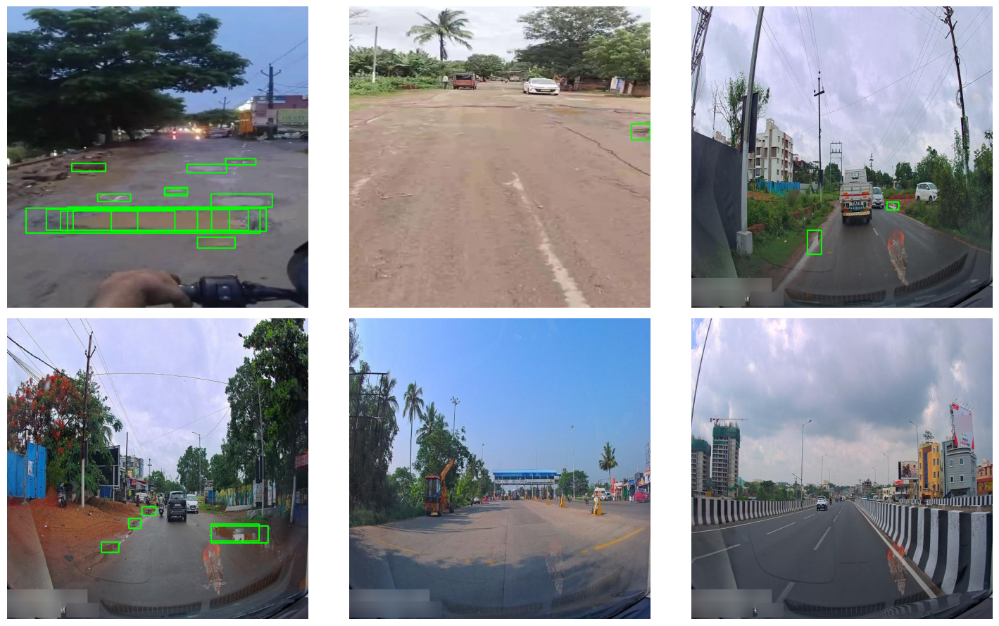

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

test_files = [
    f for f in os.listdir(test_image_dir)
    if f.lower().endswith(".jpg")
]

samples = random.sample(test_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_file in zip(axes.ravel(), samples):
    image_path = os.path.join(test_image_dir, image_file)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    prediction = best_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    for box in prediction.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = map(int, box)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Continue training to 20 epochs**

In [ ]:
last_model = YOLO(
    "/content/roadvision_runs/pothole_yolo11n/weights/last.pt"
)

results = last_model.train(
    resume=True,
    epochs=20,
    device=0
)

WARNING ⚠️ model '/content/roadvision_runs/pothole_yolo11n/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, 

**Load the new best model**

In [ ]:
BEST_MODEL = "/content/roadvision_runs/pothole_yolo11n/weights/best.pt"

best_model = YOLO(BEST_MODEL)

print("Best model loaded successfully")

Best model loaded successfully


**Evaluate the 20-epoch model on the test set**

In [ ]:
test_results = best_model.val(
    data=TRAIN_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1683.7±351.5 MB/s, size: 114.9 KB)
val: Scanning /content/BharathPothole/BharatPotHole/BharatPotHole/test/labels.cache... 662 images, 289 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 662/662 163.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 3.7it/s 11.4s
                   all        662       1150      0.511       0.41        0.4      0.135
Speed: 3.7ms preprocess, 4.7ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs/detect/val-4
Test mAP50: 0.39957396566968456
Test mAP50-95: 0.1351538407426522


**Visualize improved predictions**

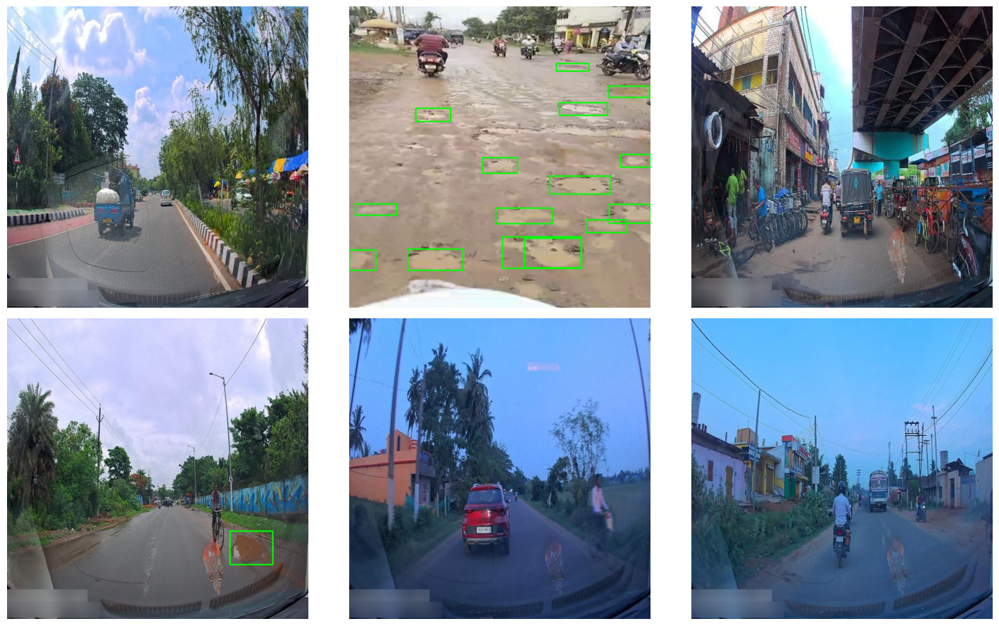

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

samples = random.sample(test_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_file in zip(axes.ravel(), samples):
    image_path = os.path.join(test_image_dir, image_file)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    prediction = best_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.35,
        device=0,
        verbose=False
    )[0]

    for box in prediction.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = map(int, box)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()

Since Cell 9 gave us the bounding-box statistics, we'll calculate the actual distribution of pothole sizes in the dataset and use that to design our severity levels.

**Analyze pothole size distribution**

In [ ]:
import numpy as np
import os

areas = []

for split in splits:
    label_dir = f"{DATASET}/{split}/labels"

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, file), "r") as f:
            for line in f:
                values = line.split()

                if len(values) != 5:
                    continue

                _, x, y, w, h = map(float, values)

                area = w * h
                areas.append(area)

areas = np.array(areas)

print("Total bounding boxes:", len(areas))
print("Minimum area:", areas.min())
print("Maximum area:", areas.max())
print("Mean area:", areas.mean())
print("Median area:", np.median(areas))

print("\nPercentiles:")
print("25th percentile:", np.percentile(areas, 25))
print("50th percentile:", np.percentile(areas, 50))
print("75th percentile:", np.percentile(areas, 75))
print("90th percentile:", np.percentile(areas, 90))
print("95th percentile:", np.percentile(areas, 95))

Total bounding boxes: 12221
Minimum area: 6.103515625000001e-07
Maximum area: 0.310717168534
Mean area: 0.005167664716357366
Median area: 0.00186032405

Percentiles:
25th percentile: 0.0007861328124999999
50th percentile: 0.00186032405
75th percentile: 0.004482421875
90th percentile: 0.011005859375
95th percentile: 0.0199658203125


**Define the severity classification**

In [ ]:
def classify_severity(area):
    if area <= 0.00186032405:
        return "Low"
    elif area <= 0.004482421875:
        return "Moderate"
    elif area <= 0.011005859375:
        return "High"
    else:
        return "Critical"

print("Severity thresholds:")
print("Low      :", "<= 0.001860")
print("Moderate :", "0.001860 - 0.004482")
print("High     :", "0.004482 - 0.011006")
print("Critical :", "> 0.011006")

Severity thresholds:
Low      : <= 0.001860
Moderate : 0.001860 - 0.004482
High     : 0.004482 - 0.011006
Critical : > 0.011006


**Check severity distribution in the dataset**

In [ ]:
severity_counts = {
    "Low": 0,
    "Moderate": 0,
    "High": 0,
    "Critical": 0
}

for area in areas:
    severity = classify_severity(area)
    severity_counts[severity] += 1

print("Severity distribution:")

for severity, count in severity_counts.items():
    percentage = (count / len(areas)) * 100
    print(f"{severity}: {count} ({percentage:.2f}%)")

Severity distribution:
Low: 6111 (50.00%)
Moderate: 3055 (25.00%)
High: 1835 (15.02%)
Critical: 1220 (9.98%)


**Create severity scoring functions**

In [ ]:
SEVERITY_WEIGHTS = {
    "Low": 1,
    "Moderate": 2,
    "High": 3,
    "Critical": 4
}

def get_severity(area):
    if area <= 0.00186032405:
        return "Low"
    elif area <= 0.004482421875:
        return "Moderate"
    elif area <= 0.011005859375:
        return "High"
    else:
        return "Critical"

def calculate_road_health(detections):
    if len(detections) == 0:
        return 100.0

    severity_scores = [
        SEVERITY_WEIGHTS[d["severity"]]
        for d in detections
    ]

    total_damage = sum(severity_scores)

    health_score = max(
        0,
        100 - (total_damage * 8)
    )

    return round(health_score, 2)

**Test the severity and health calculation**

In [ ]:
sample_detections = [
    {"severity": "Low"},
    {"severity": "Moderate"},
    {"severity": "High"},
    {"severity": "Critical"}
]

health = calculate_road_health(sample_detections)

print("Detected potholes:", len(sample_detections))
print("Severity levels:")

for detection in sample_detections:
    print(detection["severity"])

print("Road Health Score:", health)

Detected potholes: 4
Severity levels:
Low
Moderate
High
Critical
Road Health Score: 20


**Create the complete image analysis function**

In [ ]:
def analyze_road_image(image_path, conf=0.35):
    prediction = best_model.predict(
        source=image_path,
        imgsz=640,
        conf=conf,
        device=0,
        verbose=False
    )[0]

    image = cv2.imread(image_path)
    h, w = image.shape[:2]

    detections = []

    for box, confidence in zip(
        prediction.boxes.xyxy.cpu().numpy(),
        prediction.boxes.conf.cpu().numpy()
    ):
        x1, y1, x2, y2 = box

        box_width = max(0, x2 - x1)
        box_height = max(0, y2 - y1)

        relative_area = (box_width * box_height) / (w * h)

        severity = get_severity(relative_area)

        detections.append({
            "x1": int(x1),
            "y1": int(y1),
            "x2": int(x2),
            "y2": int(y2),
            "confidence": float(confidence),
            "area": float(relative_area),
            "severity": severity
        })

    health_score = calculate_road_health(detections)

    if health_score >= 80:
        condition = "Good"
        priority = "Low"
    elif health_score >= 60:
        condition = "Moderate"
        priority = "Medium"
    elif health_score >= 40:
        condition = "Poor"
        priority = "High"
    else:
        condition = "Critical"
        priority = "Urgent"

    return detections, health_score, condition, priority

**Test RoadVision AI on one test image**

In [ ]:
sample_image = os.path.join(
    test_image_dir,
    test_files[0]
)

detections, health_score, condition, priority = analyze_road_image(
    sample_image
)

print("RoadVision AI Analysis")
print("----------------------")
print("Image:", test_files[0])
print("Potholes detected:", len(detections))

for i, detection in enumerate(detections, 1):
    print(
        f"Pothole {i}: "
        f"{detection['severity']} | "
        f"Confidence: {detection['confidence']:.2f} | "
        f"Area: {detection['area']:.4f}"
    )

print("\nRoad Health Score:", health_score, "/ 100")
print("Road Condition:", condition)
print("Maintenance Priority:", priority)

RoadVision AI Analysis
----------------------
Image: 20250523181711_0060_frame_00096_jpg.rf.3f742ad177deaa58f69e7b056ecc30ab.jpg
Potholes detected: 0

Road Health Score: 100.0 / 100
Road Condition: Good
Maintenance Priority: Low


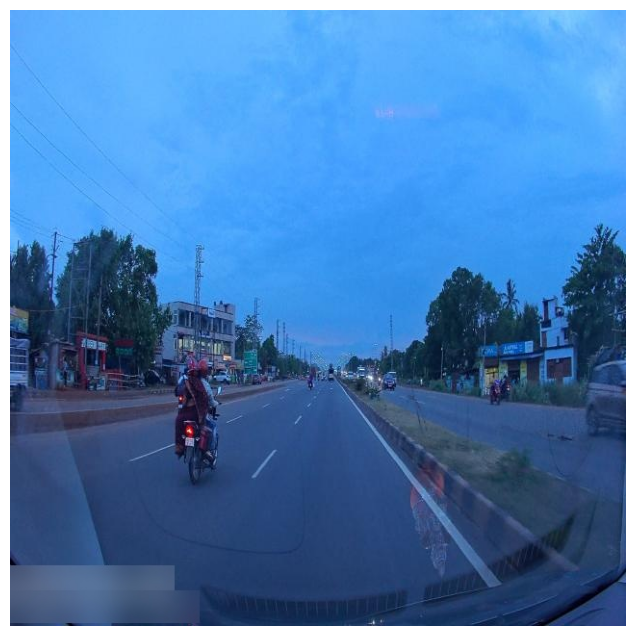

In [ ]:
image = cv2.imread(sample_image)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for detection in detections:
    cv2.rectangle(
        image,
        (detection["x1"], detection["y1"]),
        (detection["x2"], detection["y2"]),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

**Test RoadVision AI on test image(All Possible cases)**

In [ ]:
selected_cases = {}

for image_file in test_files:
    image_path = os.path.join(test_image_dir, image_file)

    detections, health_score, condition, priority = analyze_road_image(
        image_path,
        conf=0.35
    )

    count = len(detections)

    if count == 0 and "No Potholes" not in selected_cases:
        selected_cases["No Potholes"] = (
            image_file, detections, health_score, condition, priority
        )

    elif (
        0 < count <= 2
        and condition == "Good"
        and "Low" not in selected_cases
    ):
        selected_cases["Low"] = (
            image_file, detections, health_score, condition, priority
        )

    elif (
        condition == "Moderate"
        and "Moderate" not in selected_cases
    ):
        selected_cases["Moderate"] = (
            image_file, detections, health_score, condition, priority
        )

    elif (
        condition == "Poor"
        and "High" not in selected_cases
    ):
        selected_cases["High"] = (
            image_file, detections, health_score, condition, priority
        )

    elif (
        condition == "Critical"
        and count >= 15
        and "Critical" not in selected_cases
    ):
        selected_cases["Critical"] = (
            image_file, detections, health_score, condition, priority
        )

    elif (
        count >= 3
        and "Mixed" not in selected_cases
    ):
        selected_cases["Mixed"] = (
            image_file, detections, health_score, condition, priority
        )

required_cases = [
    "No Potholes",
    "Low",
    "Moderate",
    "High",
    "Critical",
    "Mixed"
]

print("Selected RoadVision AI Cases")
print("----------------------------")

for case in required_cases:
    if case in selected_cases:
        image_file, detections, health_score, condition, priority = selected_cases[case]

        print(f"\n{case}")
        print("Image:", image_file)
        print("Potholes:", len(detections))
        print("Health Score:", health_score)
        print("Condition:", condition)
        print("Priority:", priority)
    else:
        print(f"\n{case}: NOT FOUND")

Selected RoadVision AI Cases
----------------------------

No Potholes
Image: 20250523181711_0060_frame_00096_jpg.rf.3f742ad177deaa58f69e7b056ecc30ab.jpg
Potholes: 0
Health Score: 100.0
Condition: Good
Priority: Low

Low
Image: 20250528094919_0060_frame_00079_jpg.rf.5cec707de03efc7a09c736808bcbfb66.jpg
Potholes: 1
Health Score: 92
Condition: Good
Priority: Low

Moderate
Image: 20250525123300_0060_frame_00017_jpg.rf.27c0e72606aa2f65b1c68bdc340b785d.jpg
Potholes: 1
Health Score: 76
Condition: Moderate
Priority: Medium

High
Image: signal-2025-06-25-183557_frame_00095_jpg.rf.4429860203e778aa327e99f458c6da9a.jpg
Potholes: 4
Health Score: 52
Condition: Poor
Priority: High

Critical
Image: signal-2025-06-26-111944_frame_00085_jpg.rf.2a1cd758664bab401ceda0d6e1bf4098.jpg
Potholes: 15
Health Score: 0
Condition: Critical
Priority: Urgent

Mixed
Image: 20250525135447_0060_frame_00014_jpg.rf.73745df0324bcff521f722510e8a504f.jpg
Potholes: 3
Health Score: 36
Condition: Critical
Priority: Urgent


**Visualize the analysis**

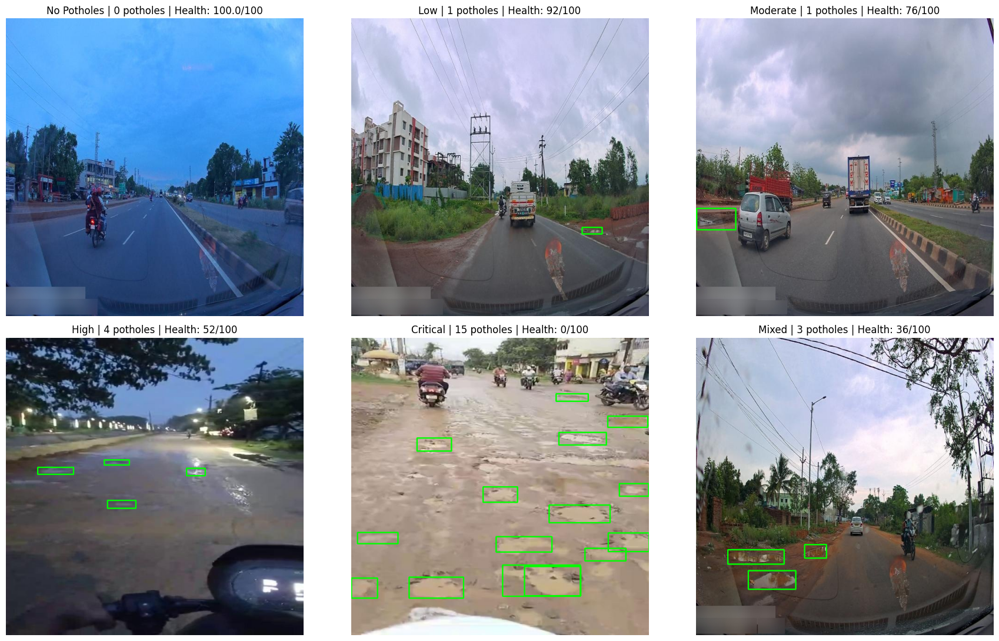

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, case in zip(axes.ravel(), required_cases):
    ax.axis("off")

    if case not in selected_cases:
        ax.set_title(f"{case}\nNot found")
        continue

    image_file, detections, health_score, condition, priority = selected_cases[case]

    image_path = os.path.join(test_image_dir, image_file)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for detection in detections:
        cv2.rectangle(
            image,
            (detection["x1"], detection["y1"]),
            (detection["x2"], detection["y2"]),
            (0, 255, 0),
            2
        )

    ax.imshow(image)
    ax.set_title(
        f"{case} | {len(detections)} potholes | "
        f"Health: {health_score}/100",
        fontsize=12
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def calculate_road_health(detections):
    if len(detections) == 0:
        return 100.0

    damage_score = 0

    for detection in detections:
        severity = detection["severity"]
        area = detection["area"]

        severity_weight = SEVERITY_WEIGHTS[severity]

        area_factor = min(area / 0.011005859375, 2.0)

        damage_score += severity_weight * (0.5 + 0.5 * area_factor)

    health_score = 100 - (damage_score * 6)

    return round(max(0, min(100, health_score)), 2)

In [ ]:
def get_road_condition(health_score):
    if health_score >= 80:
        return "Good", "Low"
    elif health_score >= 60:
        return "Moderate", "Medium"
    elif health_score >= 40:
        return "Poor", "High"
    else:
        return "Critical", "Urgent"

In [ ]:
def analyze_road_image(image_path, conf=0.35):
    prediction = best_model.predict(
        source=image_path,
        imgsz=640,
        conf=conf,
        device=0,
        verbose=False
    )[0]

    image = cv2.imread(image_path)
    h, w = image.shape[:2]

    detections = []

    for box, confidence in zip(
        prediction.boxes.xyxy.cpu().numpy(),
        prediction.boxes.conf.cpu().numpy()
    ):
        x1, y1, x2, y2 = box

        box_width = max(0, x2 - x1)
        box_height = max(0, y2 - y1)

        relative_area = (box_width * box_height) / (w * h)

        severity = get_severity(relative_area)

        detections.append({
            "x1": int(x1),
            "y1": int(y1),
            "x2": int(x2),
            "y2": int(y2),
            "confidence": float(confidence),
            "area": float(relative_area),
            "severity": severity
        })

    health_score = calculate_road_health(detections)

    condition, priority = get_road_condition(health_score)

    return detections, health_score, condition, priority

In [ ]:
def generate_road_report(image_path):
    detections, health_score, condition, priority = analyze_road_image(
        image_path
    )

    severity_counts = {
        "Low": 0,
        "Moderate": 0,
        "High": 0,
        "Critical": 0
    }

    for detection in detections:
        severity_counts[detection["severity"]] += 1

    print("ROADVISION AI REPORT")
    print("--------------------")
    print("Image:", os.path.basename(image_path))
    print("Total potholes:", len(detections))

    print("\nSeverity Distribution")

    for severity, count in severity_counts.items():
        print(f"{severity}: {count}")

    print("\nRoad Health Score:", health_score, "/ 100")
    print("Road Condition:", condition)
    print("Maintenance Priority:", priority)

    return {
        "image": os.path.basename(image_path),
        "potholes": len(detections),
        "low": severity_counts["Low"],
        "moderate": severity_counts["Moderate"],
        "high": severity_counts["High"],
        "critical": severity_counts["Critical"],
        "health_score": health_score,
        "condition": condition,
        "priority": priority
    }

In [ ]:
if "Critical" in selected_cases:
    image_file = selected_cases["Critical"][0]
elif "High" in selected_cases:
    image_file = selected_cases["High"][0]
else:
    image_file = selected_cases["Mixed"][0]

sample_image = os.path.join(test_image_dir, image_file)

report = generate_road_report(sample_image)

ROADVISION AI REPORT
--------------------
Image: signal-2025-06-26-111944_frame_00085_jpg.rf.2a1cd758664bab401ceda0d6e1bf4098.jpg
Total potholes: 15

Severity Distribution
Low: 0
Moderate: 2
High: 9
Critical: 4

Road Health Score: 0 / 100
Road Condition: Critical
Maintenance Priority: Urgent


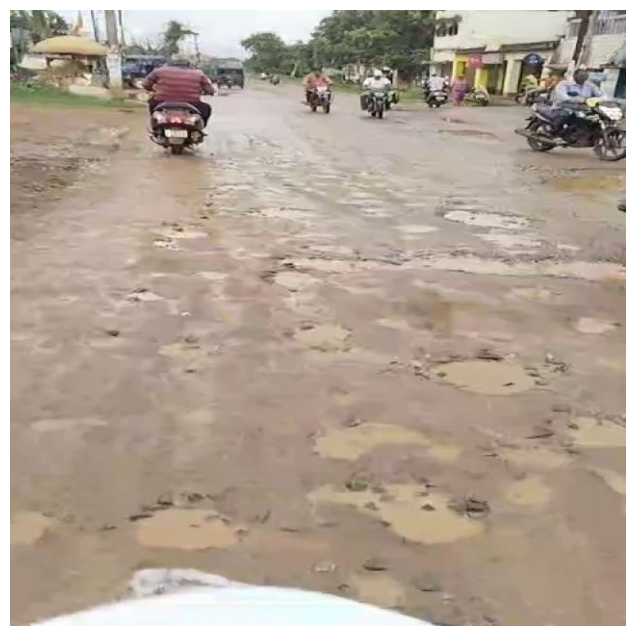

In [ ]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(sample_image)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for detection in report["detections"] if "detections" in report else []:
    x1, y1, x2, y2 = detection["x1"], detection["y1"], detection["x2"], detection["y2"]
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
# Video processing setup

import cv2
import os
from tqdm import tqdm

VIDEO_OUTPUT_DIR = "/content/roadvision_video"
os.makedirs(VIDEO_OUTPUT_DIR, exist_ok=True)

VIDEO_INPUT = "/content/sample_road_video.mp4"
VIDEO_OUTPUT = os.path.join(VIDEO_OUTPUT_DIR, "roadvision_output.mp4")

In [ ]:
# Video pothole detection

def process_video(video_input, video_output, conf=0.35):

    cap = cv2.VideoCapture(video_input)

    if not cap.isOpened():
        raise ValueError("Could not open video")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(
        video_output,
        fourcc,
        fps,
        (width, height)
    )

    frame_count = 0
    total_detections = 0

    with tqdm(total=total_frames, desc="Processing video") as pbar:

        while True:

            ret, frame = cap.read()

            if not ret:
                break

            prediction = best_model.predict(
                source=frame,
                imgsz=640,
                conf=conf,
                device=0,
                verbose=False
            )[0]

            for box in prediction.boxes.xyxy.cpu().numpy():

                x1, y1, x2, y2 = box

                box_width = max(0, x2 - x1)
                box_height = max(0, y2 - y1)

                relative_area = (
                    box_width * box_height
                ) / (width * height)

                severity = get_severity(relative_area)

                cv2.rectangle(
                    frame,
                    (int(x1), int(y1)),
                    (int(x2), int(y2)),
                    (0, 255, 0),
                    2
                )

                total_detections += 1

            writer.write(frame)

            frame_count += 1
            pbar.update(1)

    cap.release()
    writer.release()

    print("Video processing completed")
    print("Frames processed:", frame_count)
    print("Total frame detections:", total_detections)
    print("Output:", video_output)

    return {
        "frames": frame_count,
        "detections": total_detections,
        "output": video_output
    }

In [ ]:
# Unique pothole tracking

import math

def calculate_center(box):
    x1, y1, x2, y2 = box
    return (
        (x1 + x2) / 2,
        (y1 + y2) / 2
    )


def center_distance(center1, center2):
    return math.sqrt(
        (center1[0] - center2[0]) ** 2 +
        (center1[1] - center2[1]) ** 2
    )


class PotholeTracker:

    def __init__(self, max_distance=80, max_missing=10):

        self.tracks = {}
        self.next_id = 1

        self.max_distance = max_distance
        self.max_missing = max_missing

    def update(self, detections):

        current_centers = [
            calculate_center(
                (
                    d["x1"],
                    d["y1"],
                    d["x2"],
                    d["y2"]
                )
            )
            for d in detections
        ]

        matched_tracks = set()

        for detection, center in zip(
            detections,
            current_centers
        ):

            best_id = None
            best_distance = self.max_distance

            for track_id, track in self.tracks.items():

                if track_id in matched_tracks:
                    continue

                distance = center_distance(
                    center,
                    track["center"]
                )

                if distance < best_distance:
                    best_distance = distance
                    best_id = track_id

            if best_id is not None:

                self.tracks[best_id]["center"] = center
                self.tracks[best_id]["missing"] = 0
                self.tracks[best_id]["severity"] = detection["severity"]

                detection["track_id"] = best_id

                matched_tracks.add(best_id)

            else:

                track_id = self.next_id
                self.next_id += 1

                self.tracks[track_id] = {
                    "center": center,
                    "missing": 0,
                    "severity": detection["severity"]
                }

                detection["track_id"] = track_id

                matched_tracks.add(track_id)

        for track_id in list(self.tracks.keys()):

            if track_id not in matched_tracks:
                self.tracks[track_id]["missing"] += 1

                if self.tracks[track_id]["missing"] > self.max_missing:
                    del self.tracks[track_id]

        return detections

In [ ]:
# Complete video analytics

def analyze_video(video_input, video_output, conf=0.35):

    cap = cv2.VideoCapture(video_input)

    if not cap.isOpened():
        raise ValueError("Could not open video")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    writer = cv2.VideoWriter(
        video_output,
        fourcc,
        fps,
        (width, height)
    )

    tracker = PotholeTracker(
        max_distance=80,
        max_missing=10
    )

    unique_potholes = {}
    total_frame_detections = 0
    frame_count = 0

    severity_counts = {
        "Low": 0,
        "Moderate": 0,
        "High": 0,
        "Critical": 0
    }

    with tqdm(
        total=total_frames,
        desc="RoadVision AI Video Analysis"
    ) as pbar:

        while True:

            ret, frame = cap.read()

            if not ret:
                break

            prediction = best_model.predict(
                source=frame,
                imgsz=640,
                conf=conf,
                device=0,
                verbose=False
            )[0]

            detections = []

            for box, confidence in zip(
                prediction.boxes.xyxy.cpu().numpy(),
                prediction.boxes.conf.cpu().numpy()
            ):

                x1, y1, x2, y2 = box

                box_width = max(0, x2 - x1)
                box_height = max(0, y2 - y1)

                relative_area = (
                    box_width * box_height
                ) / (width * height)

                severity = get_severity(relative_area)

                detections.append({
                    "x1": int(x1),
                    "y1": int(y1),
                    "x2": int(x2),
                    "y2": int(y2),
                    "confidence": float(confidence),
                    "area": float(relative_area),
                    "severity": severity
                })

            total_frame_detections += len(detections)

            detections = tracker.update(detections)

            for detection in detections:

                track_id = detection["track_id"]

                if track_id not in unique_potholes:

                    unique_potholes[track_id] = {
                        "severity": detection["severity"],
                        "area": detection["area"],
                        "first_frame": frame_count
                    }

                    severity_counts[
                        detection["severity"]
                    ] += 1

                cv2.rectangle(
                    frame,
                    (
                        detection["x1"],
                        detection["y1"]
                    ),
                    (
                        detection["x2"],
                        detection["y2"]
                    ),
                    (0, 255, 0),
                    2
                )

            writer.write(frame)

            frame_count += 1
            pbar.update(1)

    cap.release()
    writer.release()

    unique_detections = list(
        unique_potholes.values()
    )

    health_score = calculate_road_health(
        [
            {
                "severity": d["severity"],
                "area": d["area"]
            }
            for d in unique_detections
        ]
    )

    condition, priority = get_road_condition(
        health_score
    )

    print("\nROADVISION AI VIDEO REPORT")
    print("--------------------------")
    print("Frames processed:", frame_count)
    print(
        "Total frame detections:",
        total_frame_detections
    )
    print(
        "Unique potholes:",
        len(unique_detections)
    )

    print("\nSeverity Distribution")

    for severity, count in severity_counts.items():
        print(f"{severity}: {count}")

    print("\nRoad Health Score:", health_score, "/ 100")
    print("Road Condition:", condition)
    print("Maintenance Priority:", priority)

    print("\nOutput video:", video_output)

    return {
        "frames": frame_count,
        "frame_detections": total_frame_detections,
        "unique_potholes": len(unique_detections),
        "low": severity_counts["Low"],
        "moderate": severity_counts["Moderate"],
        "high": severity_counts["High"],
        "critical": severity_counts["Critical"],
        "health_score": health_score,
        "condition": condition,
        "priority": priority,
        "output": video_output
    }

In [ ]:
print("Video analytics pipeline ready")
print("Model:", "/content/roadvision_runs/pothole_yolo11n/weights/best.pt")
print("Tracker: Enabled")
print("Severity assessment: Enabled")
print("Road health scoring: Enabled")

Video analytics pipeline ready
Model: /content/roadvision_runs/pothole_yolo11n/weights/best.pt
Tracker: Enabled
Severity assessment: Enabled
Road health scoring: Enabled


**Create Video Folders**

In [ ]:
# Create video folders

PUBLIC_VIDEO_DIR = "/content/roadvision_video/public"
os.makedirs(PUBLIC_VIDEO_DIR, exist_ok=True)

VIDEO_INPUT = os.path.join(
    PUBLIC_VIDEO_DIR,
    "road_video.mp4"
)

VIDEO_OUTPUT = os.path.join(
    PUBLIC_VIDEO_DIR,
    "roadvision_annotated.mp4"
)

print("Input:", VIDEO_INPUT)
print("Output:", VIDEO_OUTPUT)

Input: /content/roadvision_video/public/road_video.mp4
Output: /content/roadvision_video/public/roadvision_annotated.mp4


**Upload Video to Colab**

In [ ]:
# Upload road video

from google.colab import files

uploaded = files.upload()

uploaded_name = next(iter(uploaded))

uploaded_path = os.path.join(
    PUBLIC_VIDEO_DIR,
    "road_video.mp4"
)

with open(uploaded_path, "wb") as f:
    f.write(uploaded[uploaded_name])

print("Video uploaded successfully")
print("Saved as:", uploaded_path)

In [ ]:
# Check video properties

cap = cv2.VideoCapture(VIDEO_INPUT)

if not cap.isOpened():
    raise ValueError("Video could not be opened")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

duration = frame_count / fps if fps > 0 else 0

cap.release()

print("Video width:", width)
print("Video height:", height)
print("FPS:", round(fps, 2))
print("Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")

Video width: 2562
Video height: 1440
FPS: 29.97
Frames: 2056
Duration: 68.6 seconds


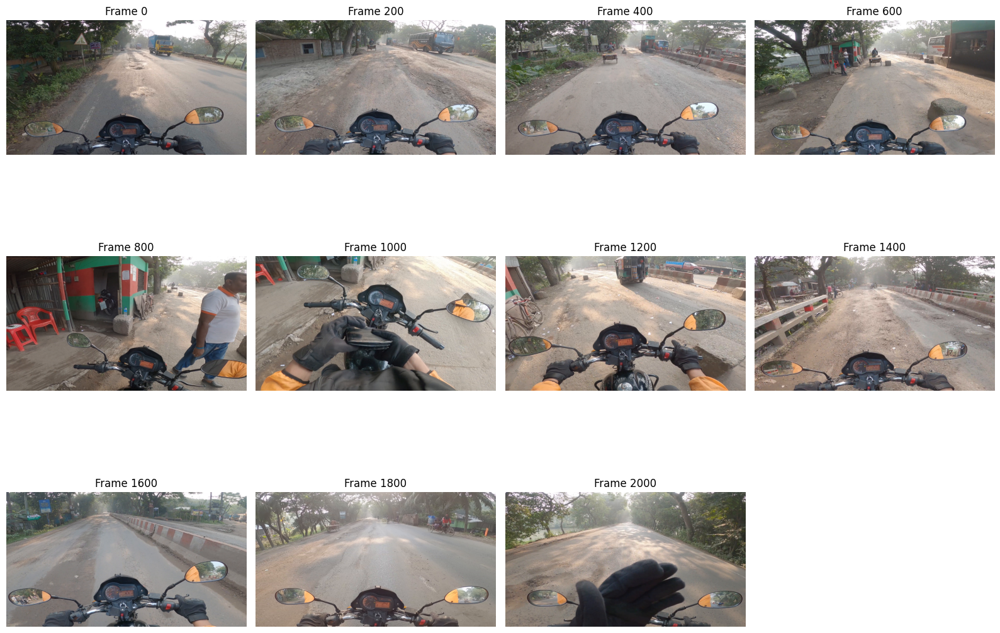

Total frames displayed: 11


In [ ]:
# Display every 400th frame in a grid

cap = cv2.VideoCapture(VIDEO_INPUT)

if not cap.isOpened():
    raise ValueError("Video could not be opened")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

frames = []
frame_numbers = []

for frame_number in range(0, total_frames, 200):

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame_rgb)
        frame_numbers.append(frame_number)

cap.release()

columns = 4
rows = (len(frames) + columns - 1) // columns

plt.figure(
    figsize=(16, rows * 4)
)

for i, frame in enumerate(frames):

    plt.subplot(rows, columns, i + 1)
    plt.imshow(frame)
    plt.title(f"Frame {frame_numbers[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total frames displayed:", len(frames))

In [ ]:
# Run RoadVision AI video analysis

video_report = analyze_video(
    VIDEO_INPUT,
    VIDEO_OUTPUT,
    conf=0.35
)

RoadVision AI Video Analysis: 100%|██████████| 2056/2056 [02:32<00:00, 13.45it/s]


ROADVISION AI VIDEO REPORT
--------------------------
Frames processed: 2056
Total frame detections: 417
Unique potholes: 62

Severity Distribution
Low: 1
Moderate: 1
High: 7
Critical: 53

Road Health Score: 0 / 100
Road Condition: Critical
Maintenance Priority: Urgent

Output video: /content/roadvision_video/public/roadvision_annotated.mp4


In [ ]:
# Display video report

print("ROADVISION AI")
print("==========================")

print("Frames processed:", video_report["frames"])

print(
    "Total frame detections:",
    video_report["frame_detections"]
)

print(
    "Unique potholes:",
    video_report["unique_potholes"]
)

print("\nSeverity Distribution")

print("Low:", video_report["low"])
print("Moderate:", video_report["moderate"])
print("High:", video_report["high"])
print("Critical:", video_report["critical"])

print("\nRoad Health Score:",
      video_report["health_score"], "/ 100")

print(
    "Road Condition:",
    video_report["condition"]
)

print(
    "Maintenance Priority:",
    video_report["priority"]
)

ROADVISION AI
Frames processed: 2056
Total frame detections: 417
Unique potholes: 62

Severity Distribution
Low: 1
Moderate: 1
High: 7
Critical: 53

Road Health Score: 0 / 100
Road Condition: Critical
Maintenance Priority: Urgent


In [ ]:
# Compare detections and unique potholes

frame_detections = video_report["frame_detections"]
unique_potholes = video_report["unique_potholes"]

print("TEMPORAL AGGREGATION")
print("====================")

print(
    "Frame-level detections:",
    frame_detections
)

print(
    "Unique potholes:",
    unique_potholes
)

if unique_potholes > 0:

    reduction = (
        1 -
        unique_potholes / frame_detections
    ) * 100

    print(
        "Repeated-detection reduction:",
        round(reduction, 2),
        "%"
    )

TEMPORAL AGGREGATION
Frame-level detections: 417
Unique potholes: 62
Repeated-detection reduction: 85.13 %


In [ ]:
# Extract evidence frames

evidence_dir = os.path.join(
    PUBLIC_VIDEO_DIR,
    "evidence"
)

os.makedirs(
    evidence_dir,
    exist_ok=True
)

cap = cv2.VideoCapture(VIDEO_OUTPUT)

total_frames = int(
    cap.get(cv2.CAP_PROP_FRAME_COUNT)
)

frame_positions = [
    0.20,
    0.40,
    0.60,
    0.80
]

saved_frames = []

for i, position in enumerate(frame_positions):

    frame_number = int(
        total_frames * position
    )

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_number
    )

    ret, frame = cap.read()

    if ret:

        output_path = os.path.join(
            evidence_dir,
            f"evidence_{i + 1}.jpg"
        )

        cv2.imwrite(
            output_path,
            frame
        )

        saved_frames.append(output_path)

cap.release()

print("Evidence frames saved:", len(saved_frames))

for path in saved_frames:
    print(path)

Evidence frames saved: 4
/content/roadvision_video/public/evidence/evidence_1.jpg
/content/roadvision_video/public/evidence/evidence_2.jpg
/content/roadvision_video/public/evidence/evidence_3.jpg
/content/roadvision_video/public/evidence/evidence_4.jpg


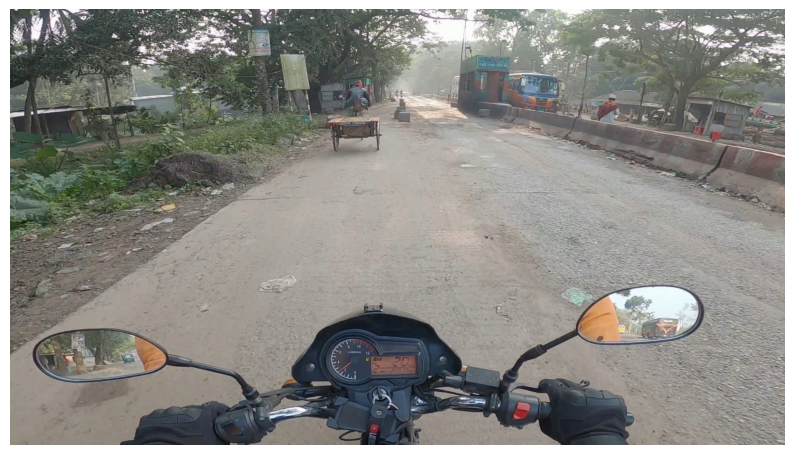

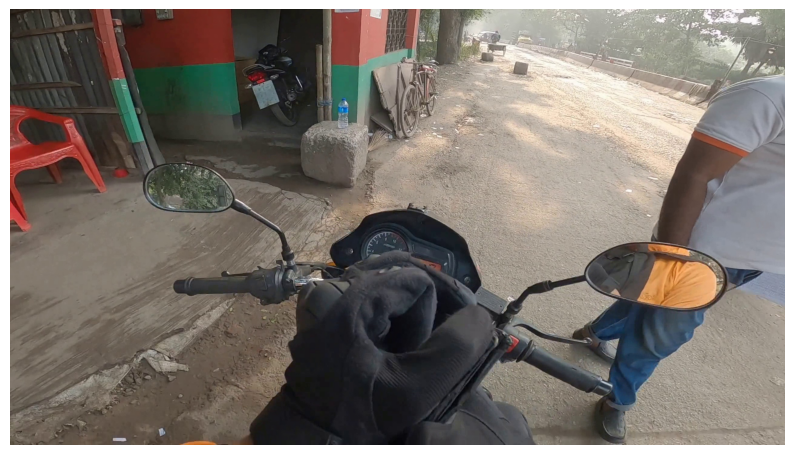

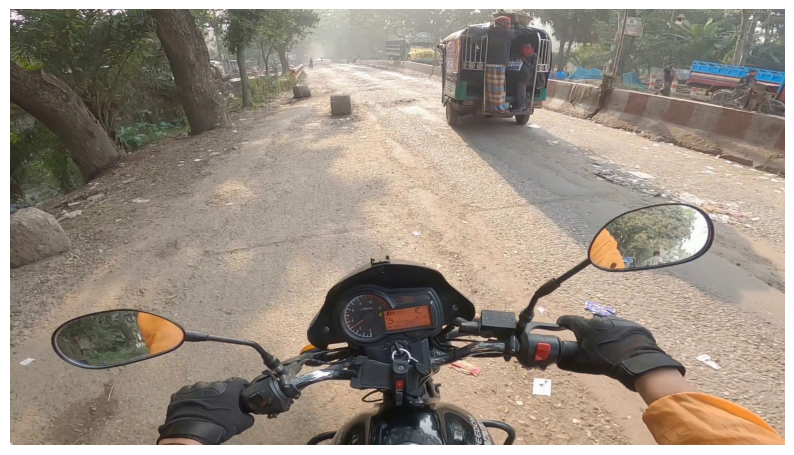

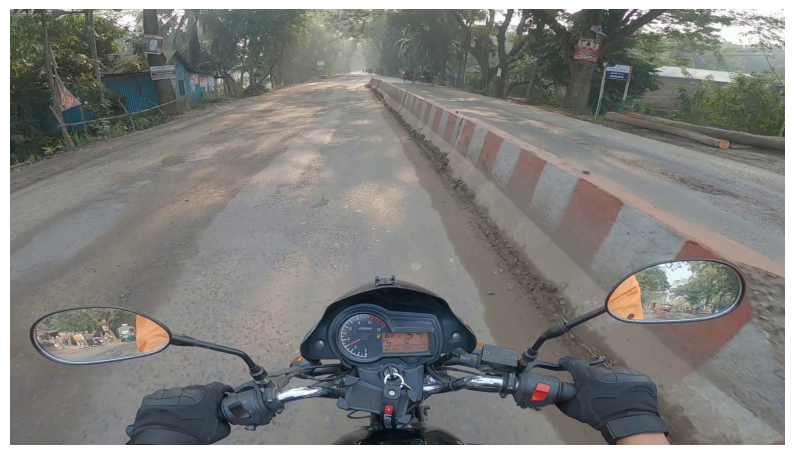

In [ ]:
# Display evidence frames

for path in saved_frames:

    image = cv2.imread(path)

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(10, 6))
    plt.imshow(image_rgb)
    plt.axis("off")
    plt.show()

In [ ]:
# Save video report

import pandas as pd

report_df = pd.DataFrame([
    {
        "Frames Processed": video_report["frames"],
        "Frame Detections": video_report["frame_detections"],
        "Unique Potholes": video_report["unique_potholes"],
        "Low": video_report["low"],
        "Moderate": video_report["moderate"],
        "High": video_report["high"],
        "Critical": video_report["critical"],
        "Road Health Score": video_report["health_score"],
        "Road Condition": video_report["condition"],
        "Maintenance Priority": video_report["priority"]
    }
])

report_path = os.path.join(
    PUBLIC_VIDEO_DIR,
    "roadvision_video_report.csv"
)

report_df.to_csv(
    report_path,
    index=False
)

print("Report saved:", report_path)

Report saved: /content/roadvision_video/public/roadvision_video_report.csv


In [ ]:
# Download final results

from google.colab import files

files.download(VIDEO_OUTPUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>